# Gym Churn: Customer Clustering

This notebook groups Model Fitness customers into clusters based on their characteristics, using hierarchical clustering to estimate the number of groups and K-means to assign customers to them. Each cluster is then profiled and compared by churn rate to identify which customer groups are most likely to leave and which are most loyal.

In [1]:
# Libraries for data handling, clustering and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)  # show all columns in outputs

## 1. Data Preparation for Clustering

In [2]:
# Load the cleaned dataset prepared in notebook 01
gym_data = pd.read_csv('../data/gym_churn_clean.csv')
gym_data.head()

,gender,near_location,partner,promo_friends,phone,contract_period,group_visits,age,avg_additional_charges_total,month_to_end_contract,lifetime,avg_class_frequency_total,avg_class_frequency_current_month,churn
0,1,1,1,1,0,6,1,29,14.227470,5,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1,3,1.113884,1.120078,0


In [3]:
# Set the churn column aside: clusters are built only from customer characteristics
# One feature from each highly correlated pair is dropped, as in notebook 02
X = gym_data.drop(
    columns=['churn', 'month_to_end_contract', 'avg_class_frequency_total'])

print(X.shape)

(4000, 11)


In [4]:
# Standardize features so that all of them contribute equally to the distances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Observations
- The churn column is set aside, so clusters are based only on customer characteristics; churn is used later to compare the clusters.
- As in the modeling notebook, `month_to_end_contract` and `avg_class_frequency_total` are excluded, since they almost duplicate other features and would be counted twice in the distance calculations.
- All features are standardized so that each contributes equally to the distances between customers. The scaler is fitted on the full dataset, since clustering does not involve a validation set.

## 2. Number of Clusters (Dendrogram)

In [5]:
# Build the linkage matrix (distances between customers) using Ward's method
linked = linkage(X_scaled, method='ward')

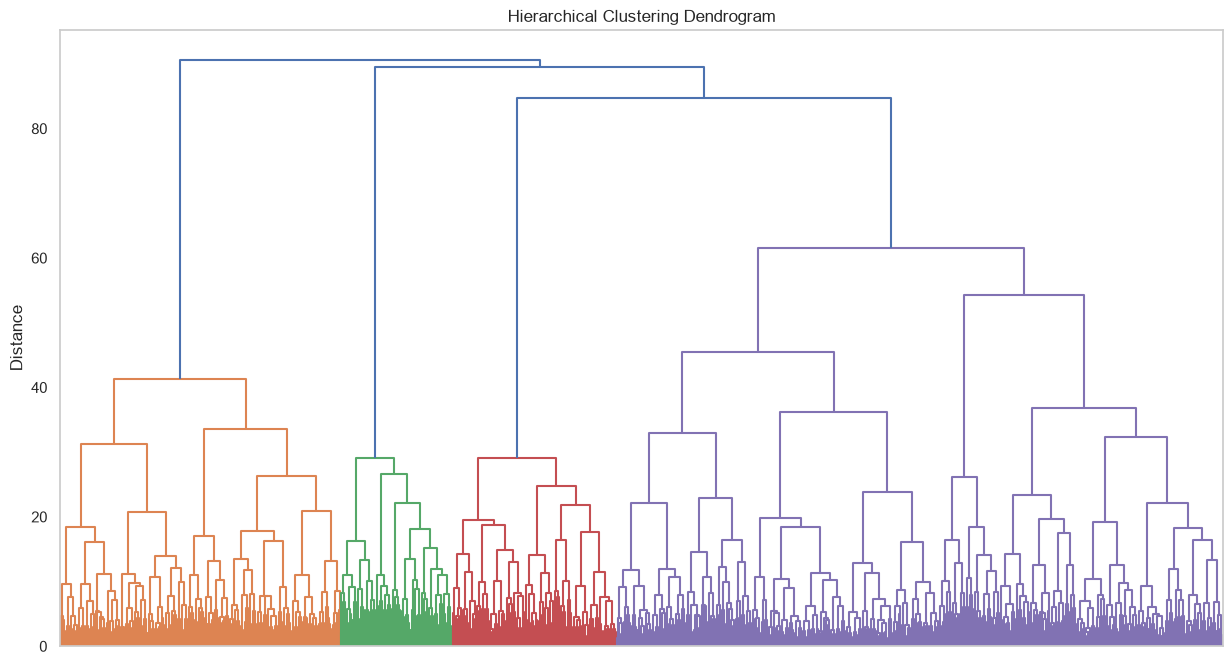

In [6]:
# Plot the dendrogram to estimate the number of clusters
plt.figure(figsize=(15, 8))
dendrogram(linked, orientation='top', no_labels=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.ylabel('Distance')
plt.grid(False)
plt.show()

### Observations
- The largest vertical gap without merges is between distances of about 62 and 85; cutting there gives 4 clusters, shown in different colors.
- A second, smaller gap between about 55 and 61 splits the largest (purple) group in two, giving 5 clusters.
- The dendrogram therefore suggests 4 or 5 clusters. Five clusters are used for K-means, as specified in the project, which is consistent with this analysis.

## 3. K-means Clustering

In [7]:
# Train K-means with 5 clusters and assign each customer to a cluster
km = KMeans(n_clusters=5, random_state=0)
clusters = km.fit_predict(X_scaled)

# Add the cluster labels to the full dataset, which still includes churn
gym_data['cluster'] = clusters

In [8]:
# Number and share of customers in each cluster
cluster_sizes = pd.DataFrame({
    'customers': gym_data['cluster'].value_counts().sort_index(),
    'share_%': (gym_data['cluster'].value_counts(normalize=True).sort_index() * 100).round(1)
})
cluster_sizes

,customers,share_%
cluster,,
0,1118,28.0
1,961,24.0
2,1035,25.9
3,600,15.0
4,286,7.2


### Observations
- K-means splits the customers into five clusters: three of similar size, clusters 0, 2 and 1 (1,118, 1,035 and 961 customers, or 28.0%, 25.9% and 24.0%), one medium-sized, cluster 3 (600 customers, 15.0%), and one small, cluster 4 (286 customers, 7.2%).
- Cluster numbers are only labels and have no meaning on their own; each cluster is described by its profile in the next section.

## 4. Cluster Profiles

In [9]:
# Average feature values per cluster (including churn and the features excluded from clustering)
gym_data.groupby('cluster').mean().T.round(3)

cluster,0,1,2,3,4
gender,0.488,0.554,0.490,0.498,0.549
near_location,1.000,1.000,0.995,0.000,0.951
partner,0.190,0.406,0.902,0.495,0.399
promo_friends,0.072,0.007,1.000,0.075,0.234
phone,0.900,0.926,0.900,0.912,0.839
contract_period,1.820,6.570,6.965,2.963,4.857
group_visits,0.275,0.540,0.521,0.227,0.517
age,27.516,30.802,29.590,28.682,29.853
avg_additional_charges_total,119.280,177.136,152.705,137.139,153.350
month_to_end_contract,1.758,6.007,6.383,2.802,4.427


### Observations
- **Cluster 0 – New, low-engagement customers (highest churn):** the largest group (1,118 customers). All live or work near the gym, but they have the shortest contracts (1.82 months on average), the shortest lifetime (1.95 months) and the lowest visit frequency in the current month (1.20 visits per week). They are the youngest group (27.5 years), spend the least on additional services (119.28), rarely attend group sessions (0.28), and few are employees of partner companies (0.19) or joined through the friend promo (0.07). Their churn rate is the highest of all clusters (0.58).
- **Cluster 1 – Engaged, high-spending customers (very low churn):** this group (961 customers) all live or work near the gym and have long contracts (6.57 months on average) and a moderate lifetime (3.53 months). They are the most engaged group: the highest visit frequency in the current month (2.30 visits per week), the highest spending on additional services (177.14) and the highest share attending group sessions (0.54). They are also the oldest group (30.8 years), and almost none joined through the friend promo (0.01). Their churn rate is very low (0.03).
- **Cluster 2 – Partner-company referrals (low churn):** in this group (1,035 customers), all joined through the bring-a-friend promo (1.00) and most are employees of partner companies (0.90), which matches the correlation between these two features found in the EDA. They have the longest contracts (6.97 months on average) and the second-longest lifetime (3.73 months). About half attend group sessions (0.52), and they visit the gym about 1.9 times per week in the current month (1.89), less often than cluster 1. Even so, their churn rate is low (0.13), suggesting that social ties and long contracts support retention even without very high engagement.
- **Cluster 3 – Non-local customers (high churn):** in this group (600 customers), none live or work near the gym (0.00), which is what defines it. They have short contracts (2.96 months on average), a short lifetime (2.78 months) and low visit frequency in the current month (1.59 visits per week). They have the lowest participation in group sessions (0.23), and few joined through the friend promo (0.08). Their churn rate is high (0.41), the second highest after cluster 0, consistent with the EDA finding that customers who are not near the gym churn more. Distance likely makes regular attendance harder.
- **Cluster 4 – Long-standing loyal customers (no churn):** this small group (286 customers) is defined by a much longer lifetime than any other cluster (13.28 months on average). They have moderate contracts (4.86 months), about half attend group sessions (0.52), and they have the second-highest spending on additional services (153.35) and the second-highest visit frequency in the current month (2.11 visits per week). None of them churned (0.00). This confirms the EDA finding that the first months are critical for retention: customers who stay long enough become very loyal.

### Feature Distributions by Cluster

In [10]:
# Plot the distribution of a feature for each cluster
def plot_cluster_distribution(data, col, label):
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=data, x='cluster', y=col,
                medianprops={'color': 'red', 'linewidth': 2})
    plt.title(f'{label} by Cluster')
    plt.xlabel('Cluster')
    plt.ylabel(label)
    plt.grid(False)
    sns.despine()
    plt.show()

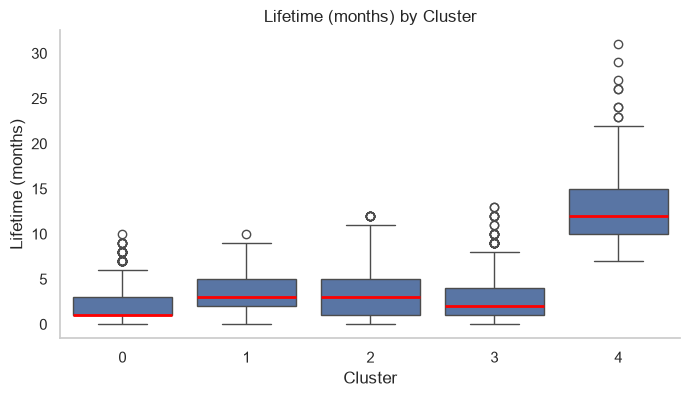

In [11]:
plot_cluster_distribution(gym_data, 'lifetime', 'Lifetime (months)')

**Lifetime:**
- Clusters 0 to 3 overlap heavily, with most customers between 1 and 5 months, so lifetime does not separate them well.
- Cluster 4 sits clearly above all others (most customers between 10 and 15 months), which confirms lifetime as its defining feature.
- Cluster 0 has the lowest values: its median equals the 25th percentile (1 month), meaning at least half of its customers have been at the gym for one month or less. Combined with its high churn rate, this confirms it as the group of newcomers who leave early. The mean lifetime in cluster 0 (1.95) is higher than its median because the distribution is right-skewed, with a few customers reaching 7 to 10 months.

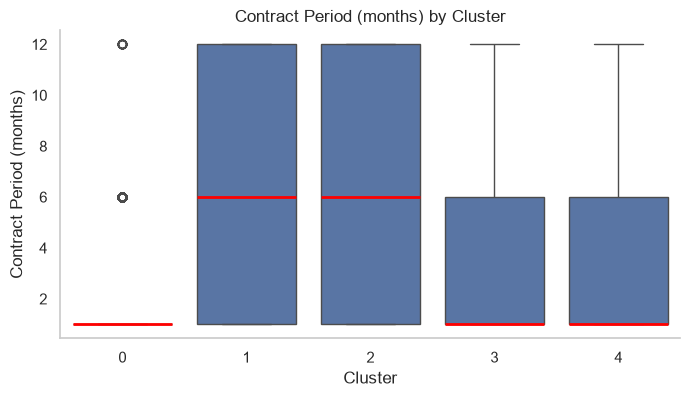

In [12]:
plot_cluster_distribution(gym_data, 'contract_period',
                          'Contract Period (months)')

**Contract period:**
- Clusters 1 and 2 have the longest contracts: their median is 6 months and many customers are on 12-month contracts.
- Cluster 0 is almost entirely on 1-month contracts: its box collapses into a single line because the 25th, 50th and 75th percentiles are all 1 month. The 6- and 12-month contracts appear as outliers, but they represent the remaining minority of the group.
- Clusters 3 and 4 have identical boxplots, since contract period only takes three values (1, 6 and 12) and both share the same percentiles. However, their means differ (2.96 vs 4.86 months), showing that cluster 4 has a higher share of longer contracts, a difference the boxplot cannot capture.

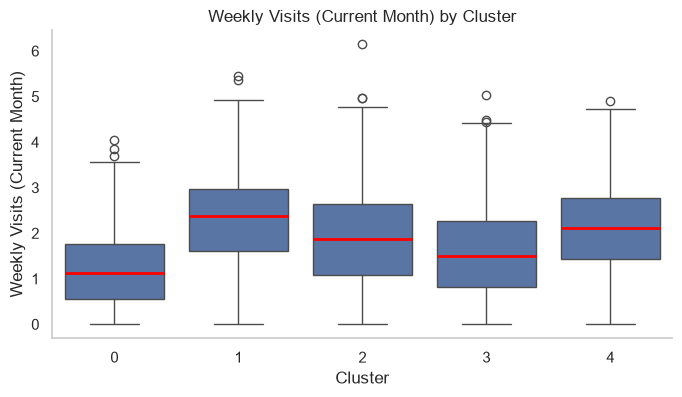

In [13]:
plot_cluster_distribution(
    gym_data, 'avg_class_frequency_current_month', 'Weekly Visits (Current Month)')

**Weekly visits (current month):**
- The ordering of the medians closely follows the churn rates: the high-churn clusters (0 and 3) have the lowest visit frequency, the low-churn clusters (1 and 4) the highest, and cluster 2 sits in between.
- Cluster 0 has the lowest values, with a median of about 1 visit per week; most of its customers visit fewer than 2 times per week.
- Cluster 1 has the highest values, with a median of about 2.4 visits per week.
- Every cluster includes customers with no visits in the current month, so even loyal groups have some inactive customers.

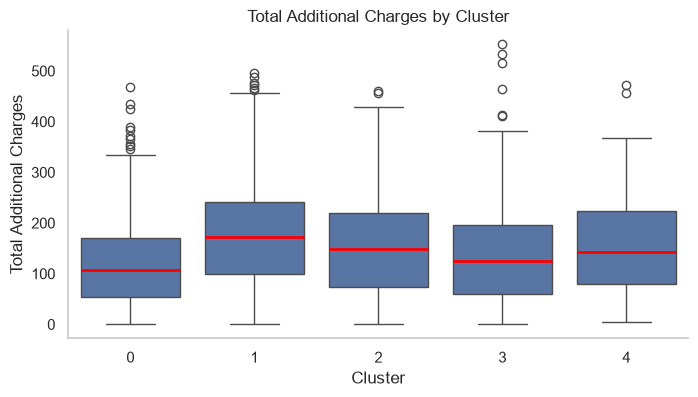

In [14]:
plot_cluster_distribution(
    gym_data, 'avg_additional_charges_total', 'Total Additional Charges')

**Additional charges:**
- The medians only partly follow the churn rates: the high-churn clusters (0 and 3) spend the least and cluster 1 the most, but cluster 4, with no churn, has a median close to cluster 2 (churn rate of 0.13).
- Cluster 0 has the lowest values, with a median of about 105; half of its customers spend between about 50 and 170.
- Cluster 1 has the highest values, with a median of about 170.
- The boxes overlap considerably across all clusters, so additional spending separates the groups less clearly than visit frequency, consistent with its smaller coefficient in the churn model.
- Every cluster includes customers who spent little or nothing on additional services.

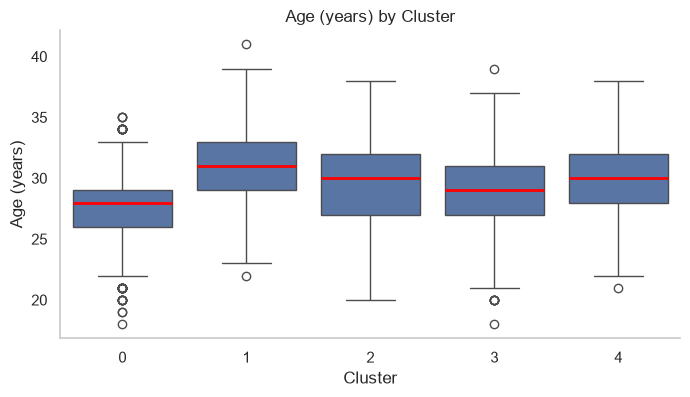

In [15]:
plot_cluster_distribution(gym_data, 'age', 'Age (years)')

**Age:**
- Younger clusters tend to churn more: cluster 0, the youngest (median of 28 years), has the highest churn rate, followed by cluster 3 (median of 29), while the oldest clusters (1, 2 and 4, with medians of 30 to 31) have low churn.
- However, the differences between clusters are small: medians range only from 28 to 31 years and the boxes overlap considerably, consistent with the homogeneous age distribution found in the EDA. Age follows the churn pattern but is not what separates the groups.
- Cluster 0 is the youngest and has the narrowest box, with half of its customers between 26 and 29 years.


## 5. Churn Rate by Cluster

In [16]:
# Churn rate per cluster, from highest to lowest
churn_by_cluster = gym_data.groupby(
    'cluster')['churn'].mean().sort_values(ascending=False)
churn_by_cluster.round(2)

cluster
0    0.58
3    0.41
2    0.13
1    0.03
4    0.00
Name: churn, dtype: float64

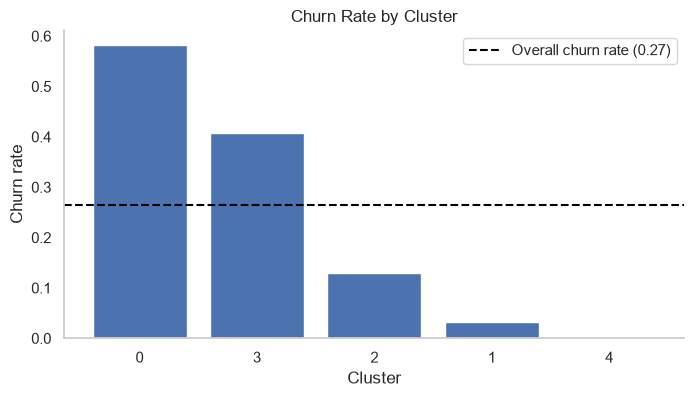

In [17]:
# Bar chart of churn rate per cluster, with the overall churn rate as reference
overall_rate = gym_data['churn'].mean()

plt.figure(figsize=(8, 4))
plt.bar(churn_by_cluster.index.astype(str), churn_by_cluster)
plt.axhline(overall_rate, color='black', linestyle='--',
            label=f'Overall churn rate ({overall_rate:.2f})')
plt.title('Churn Rate by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Churn rate')
plt.legend()
plt.grid(False)
sns.despine()
plt.show()

**Churn rate by cluster:**
- Churn differs sharply between clusters, from 0.58 in cluster 0 to 0.00 in cluster 4, compared with an overall rate of 0.27.
- Clusters 0 and 3 are the most likely to churn, both above the overall rate: cluster 0 (new, low-engagement customers, 0.58) and cluster 3 (non-local customers, 0.41).
- Clusters 4, 1 and 2 are the most loyal, well below the overall rate: cluster 4 (long-standing customers, 0.00), cluster 1 (engaged, high-spending customers, 0.03) and cluster 2 (partner-company referrals, 0.13).
- The high-churn profiles match the risk factors found in the EDA and the churn model: short lifetime, short contracts and low visit frequency. Retention efforts should focus first on cluster 0, the largest group and the one with the highest churn, followed by cluster 3.